# Bureau & Bureau Balance – Feature Engineering

Cleans and aggregates the `bureau` and `bureau_balance` datasets for the Home Credit default prediction pipeline.

**Pipeline overview**
1. Load data & restrict to training customers
2. Impute missing credit-sum values
3. Bureau Balance: clean, impute & derive status features
4. Aggregate bureau balance to loan level (all-time + time windows)
5. Derive Bureau-level ratio features
6. Merge balance aggregates onto Bureau
7. Aggregate Bureau to customer level (numeric means + count features)
8. Quality checks & save

## 1. Imports & Configuration

In [29]:
import os
import pandas as pd
import numpy as np
import gc;

DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"A:\Dominic\My Projects\Home Credit\data")


PATH_APP_TRAIN = os.path.join(DATA_ROOT, "Input", "application_train.csv")
PATH_BUREAU    = os.path.join(DATA_ROOT, "Input", "bureau.csv")
PATH_BUREAU_BAL= os.path.join(DATA_ROOT, "Input", "bureau_balance.csv")
PATH_OUTPUT    = os.path.join(DATA_ROOT, "Model-Training", "Staging","bureau_processed.parquet")

## 2. Load Data

> **Fix:** the original loaded `base` with `TARGET` but never used it to filter `Bureau`
> to training customers — bureau records for test-set customers contaminated the feature
> set. We now load only `SK_ID_CURR` from `base` and apply an inner merge to restrict
> `Bureau` upfront. `logging` was also imported but never used — removed.

In [30]:
# Load only SK_ID_CURR — TARGET is not needed here
base = pd.read_csv(PATH_APP_TRAIN, usecols=['SK_ID_CURR'])
base = base.astype({'SK_ID_CURR': 'string'})

Bureau = pd.read_csv(PATH_BUREAU)
Bureau = Bureau.astype({'SK_ID_CURR': 'string', 'SK_ID_BUREAU': 'string'})

# FIX: restrict Bureau to training customers before any processing
Bureau = Bureau.merge(base, on='SK_ID_CURR', how='inner')
Bureau.sort_values(by=['SK_ID_CURR', 'DAYS_CREDIT'], ascending=[True, False], inplace=True, ignore_index=True)

BureauBal = pd.read_csv(PATH_BUREAU_BAL)
BureauBal = BureauBal.astype({'SK_ID_BUREAU': 'string'})

print(f"Bureau    shape: {Bureau.shape}")
print(f"BureauBal shape: {BureauBal.shape}")

Bureau    shape: (1465325, 17)
BureauBal shape: (27299925, 3)


## 3. Impute Missing Credit-Sum Values

The imputation rules follow the data dictionary semantics for each credit type:

| Condition | Column | Rule |
|---|---|---|
| Closed credits | `AMT_CREDIT_SUM_LIMIT`, `AMT_CREDIT_SUM_DEBT` | → `0` (fully settled) |
| Active, non-card credits | `AMT_CREDIT_SUM_LIMIT` | → `0` (consumer credits have no revolving limit) |
| Active, non-card credits | `AMT_CREDIT_SUM_DEBT` | → `AMT_CREDIT_SUM` (full balance assumed outstanding) |
| Active credit cards | `AMT_CREDIT_SUM_LIMIT` | → `AMT_CREDIT_SUM − AMT_CREDIT_SUM_DEBT`, floored at 0 |

In [31]:
# Closed credits: limit and debt are 0
closed = Bureau['CREDIT_ACTIVE'] == 'Closed'
Bureau.loc[closed & Bureau['AMT_CREDIT_SUM_LIMIT'].isna(), 'AMT_CREDIT_SUM_LIMIT'] = 0
Bureau.loc[closed & Bureau['AMT_CREDIT_SUM_DEBT'].isna(),  'AMT_CREDIT_SUM_DEBT']  = 0

# Active non-card: limit = 0, debt = full credit sum
active_noncredit = (Bureau['CREDIT_ACTIVE'] == 'Active') & (Bureau['CREDIT_TYPE'] != 'Credit card')
Bureau.loc[active_noncredit & Bureau['AMT_CREDIT_SUM_LIMIT'].isna(), 'AMT_CREDIT_SUM_LIMIT'] = 0
Bureau.loc[active_noncredit & Bureau['AMT_CREDIT_SUM_DEBT'].isna(),  'AMT_CREDIT_SUM_DEBT']  = (
    Bureau.loc[active_noncredit & Bureau['AMT_CREDIT_SUM_DEBT'].isna(), 'AMT_CREDIT_SUM']
)

# Active credit cards: limit = max(credit_sum - debt, 0)
active_card = (Bureau['CREDIT_ACTIVE'] == 'Active') & (Bureau['CREDIT_TYPE'] == 'Credit card')
card_limit_null = active_card & Bureau['AMT_CREDIT_SUM_LIMIT'].isna()
Bureau.loc[card_limit_null, 'AMT_CREDIT_SUM_LIMIT'] = np.where(
    Bureau.loc[card_limit_null, 'AMT_CREDIT_SUM'] > Bureau.loc[card_limit_null, 'AMT_CREDIT_SUM_DEBT'],
    Bureau.loc[card_limit_null, 'AMT_CREDIT_SUM'] - Bureau.loc[card_limit_null, 'AMT_CREDIT_SUM_DEBT'],
    0,
)

print("Credit-sum imputation complete.")
print("Remaining nulls in imputed columns:")
print(Bureau[['AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_DEBT']].isna().sum().to_string())

Credit-sum imputation complete.
Remaining nulls in imputed columns:
AMT_CREDIT_SUM_LIMIT     4212
AMT_CREDIT_SUM_DEBT     24940


## 4. Bureau Balance: Join, Sort & Impute

`STATUS` codes: `0`=no DPD, `1–5`=DPD bucket, `C`=closed, `X`=unknown.

`X` is treated as missing and imputed with forward/back-fill (limit 3 months).

> **Fix:** the original sorted `BureauBal` *before* joining `SK_ID_CURR` from `Bureau`.
> The merge reorders rows, invalidating the sort. Sort is now applied *after* the join,
> and `SK_ID_CURR` is included in the sort keys so `.first()` / `.last()` within a
> `groupby('SK_ID_BUREAU')` operate on chronologically ordered data.

In [32]:
# Join SK_ID_CURR from Bureau (only bureau IDs present in training set)
BureauBal = Bureau[['SK_ID_BUREAU', 'SK_ID_CURR']].merge(
    BureauBal, on='SK_ID_BUREAU', how='inner'
)

# FIX: sort AFTER join — merge does not preserve row order
BureauBal.sort_values(
    by=['SK_ID_CURR', 'SK_ID_BUREAU', 'MONTHS_BALANCE'],
    inplace=True, ignore_index=True,
)

# Impute STATUS: replace 'X' with NaN then forward/back-fill within each loan
BureauBal['STATUS_FILLED'] = (
    BureauBal.groupby('SK_ID_BUREAU')['STATUS']
    .transform(lambda x: x.replace('X', np.nan).ffill(limit=3).bfill(limit=3))
)

# Status-change flag: 1 if status differs from the previous month
BureauBal['STATUS_LAG1'] = BureauBal.groupby('SK_ID_BUREAU')['STATUS_FILLED'].shift(1)
BureauBal['STATUS_NE_STATUS_LAG1'] = (
    BureauBal['STATUS_FILLED'] != BureauBal['STATUS_LAG1']
).astype(int)

print(f"BureauBal shape after join: {BureauBal.shape}")

C:\Users\domjo\AppData\Local\Temp\ipykernel_19520\2309759431.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.replace('X', np.nan).ffill(limit=3).bfill(limit=3))


BureauBal shape after join: (14701612, 7)


<Axes: title={'center': 'Bureau Balance: MONTHS_BALANCE distribution'}, ylabel='Frequency'>

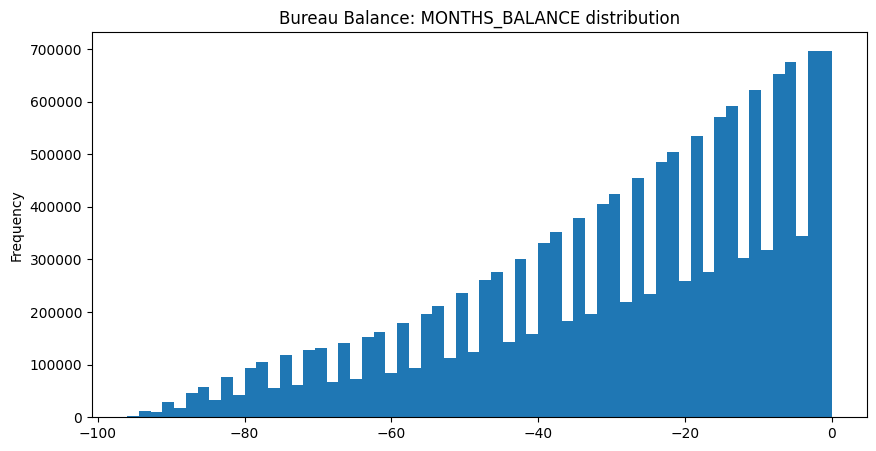

In [33]:
BureauBal['MONTHS_BALANCE'].plot.hist(bins=60, figsize=(10, 5), title='Bureau Balance: MONTHS_BALANCE distribution')

In [34]:
BureauBal[BureauBal['MONTHS_BALANCE'] < -24]['SK_ID_CURR'].nunique() / BureauBal['SK_ID_CURR'].nunique() * 100

83.34291073500233

## 5. Aggregate Bureau Balance to Loan Level

All aggregations are at `SK_ID_BUREAU` (loan) level. They will be joined onto
`Bureau` in Section 6.

> **Fix:** `'last'` in `.agg()` may skip `NaN` in pandas ≥ 2.0. Replaced with
> `lambda x: x.iloc[-1]` to guarantee the literal last row is returned.

> **Fix:** `DAYS_TO_DPD_GE1` was misnamed — the unit is *months*,
> not days. Renamed to `MONTHS_TO_DPD_GE1` and multiplied by 30
> to convert to approximate days for consistency with other notebooks.

In [35]:
DPD_STATUSES = ['1', '2', '3', '4', '5']
GOOD_STATUSES = ['0', 'C']

# ── All-time per-loan summary ─────────────────────────────────────────────
BureauBal_Full = (
    BureauBal.groupby('SK_ID_BUREAU').agg(
        DURATION=('MONTHS_BALANCE', lambda x: x.max() - x.min()),
        # FIX: iloc[-1] always returns literal last row (not NaN-skipping 'last')
        LAST_STATUS=('STATUS_FILLED', lambda x: x.iloc[-1]),
        NUM_STATUS_CHANGES=('STATUS_NE_STATUS_LAG1', 'sum'),
        DAYS_WITH_NO_DPD=('STATUS_FILLED', lambda x: x.isin(GOOD_STATUSES).sum()),
        DAYS_IN_DPD_GE1=('STATUS_FILLED', lambda x: x.isin(DPD_STATUSES).sum()),
    )
    .reset_index()
)

# ── Days from credit start to first DPD event ─────────────────────────────
BureauBal_DPDge1 = (
    BureauBal[BureauBal['STATUS_FILLED'].isin(DPD_STATUSES)]
    .groupby('SK_ID_BUREAU')[['MONTHS_BALANCE']]
    .first()
    .reset_index()
    .rename(columns={'MONTHS_BALANCE': 'MONTH_DPD_GE1'})
)
BureauBal_First_Snapshot = (
    BureauBal.groupby('SK_ID_BUREAU')[['MONTHS_BALANCE']]
    .first()
    .reset_index()
)
BureauBal_DPDge1 = BureauBal_DPDge1.merge(
    BureauBal_First_Snapshot, on='SK_ID_BUREAU', how='left'
)
# FIX: renamed from DAYS_ to MONTHS_ (unit is months); multiply by 30 for approx days
BureauBal_DPDge1['MONTHS_TO_DPD_GE1'] = (
    BureauBal_DPDge1['MONTH_DPD_GE1'] - BureauBal_DPDge1['MONTHS_BALANCE']
)
BureauBal_DPDge1 = BureauBal_DPDge1[['SK_ID_BUREAU', 'MONTHS_TO_DPD_GE1']]

print(f"BureauBal_Full shape  : {BureauBal_Full.shape}")
print(f"BureauBal_DPDge1 shape: {BureauBal_DPDge1.shape}")

BureauBal_Full shape  : (523515, 6)
BureauBal_DPDge1 shape: (67962, 2)


### 5b. Time-Window DPD Aggregations

Four rolling windows at loan level — merged onto `bureaubal_aggregated` in Section 6
with activity flags (`BUREAUCREDIT_IS_IN_LAST_*`).

In [36]:
def build_bal_window_agg(df, months_back, suffix):
    """Aggregate STATUS-based DPD metrics over the most recent *months_back* months."""
    window = df[df['MONTHS_BALANCE'] >= months_back]
    return (
        window.groupby('SK_ID_BUREAU').agg(**{
            f'DAYS_WITH_NO_DPD{suffix}': ('STATUS_FILLED', lambda x: x.isin(GOOD_STATUSES).sum()),
            f'NUM_STATUS_CHANGES{suffix}': ('STATUS_NE_STATUS_LAG1', 'sum'),            
            f'DAYS_IN_DPD_GE1{suffix}': ('STATUS_FILLED', lambda x: x.isin(DPD_STATUSES).sum()),
        })
        .reset_index()
    )

BureauBal_DPD_3Y = build_bal_window_agg(BureauBal, -36, '_LAST3Y')
BureauBal_DPD_2Y = build_bal_window_agg(BureauBal, -24, '_LAST2Y')
BureauBal_DPD_1Y = build_bal_window_agg(BureauBal, -12, '_LAST1Y')
BureauBal_DPD_6M = build_bal_window_agg(BureauBal,  -6, '_LAST6M')
BureauBal_DPD_3M = build_bal_window_agg(BureauBal,  -3, '_LAST3M')

del BureauBal, BureauBal_First_Snapshot
import gc; gc.collect()
print("Window aggregations complete.")

Window aggregations complete.


## 6. Merge Balance Aggregates onto Bureau

> **Fix:** the original added `HAS_CREDIT_BUREAU_BALANCE_INFO` to
> `bureaubal_aggregated` after merging *Bureau* with it — but the `_merge` indicator
> column lives on `Bureau` (the result of the merge), not on `bureaubal_aggregated`.
> This caused a `KeyError` at runtime. The flag is now correctly added to `Bureau`
> (which holds `_merge`) and `_merge` is then dropped from `Bureau`.

In [37]:
def flag_merge(left, right, on, flag_col):
    """Left-merge and add a binary flag: 1 if matched, 0 if not."""
    merged = left.merge(right, on=on, how='left', indicator=True)
    merged[flag_col] = (merged['_merge'] == 'both').astype(int)
    return merged.drop(columns=['_merge'])


# Build loan-level balance feature table
bureaubal_aggregated = Bureau[['SK_ID_BUREAU']].copy()
bureaubal_aggregated = bureaubal_aggregated.merge(BureauBal_Full,  on='SK_ID_BUREAU', how='left')
bureaubal_aggregated = bureaubal_aggregated.merge(BureauBal_DPDge1, on='SK_ID_BUREAU', how='left')
bureaubal_aggregated = flag_merge(bureaubal_aggregated, BureauBal_DPD_3Y, 'SK_ID_BUREAU', 'IS_IN_LAST_3Y')
bureaubal_aggregated = flag_merge(bureaubal_aggregated, BureauBal_DPD_2Y, 'SK_ID_BUREAU', 'IS_IN_LAST_2Y')
bureaubal_aggregated = flag_merge(bureaubal_aggregated, BureauBal_DPD_1Y, 'SK_ID_BUREAU', 'IS_IN_LAST_1Y')
bureaubal_aggregated = flag_merge(bureaubal_aggregated, BureauBal_DPD_6M, 'SK_ID_BUREAU', 'IS_IN_LAST_6M')
bureaubal_aggregated = flag_merge(bureaubal_aggregated, BureauBal_DPD_3M, 'SK_ID_BUREAU', 'IS_IN_LAST_3M')

del BureauBal_Full, BureauBal_DPDge1, BureauBal_DPD_3Y, BureauBal_DPD_2Y, BureauBal_DPD_1Y, BureauBal_DPD_6M, BureauBal_DPD_3M
gc.collect()

# FIX: merge Bureau with balance aggs; flag belongs on Bureau (holds _merge), not bureaubal_aggregated
Bureau = flag_merge(Bureau, bureaubal_aggregated, 'SK_ID_BUREAU', 'HAS_BALANCE_INFO')

del bureaubal_aggregated
print(f"Bureau shape after balance merge: {Bureau.shape}")

Bureau shape after balance merge: (1465325, 44)


In [38]:
Bureau.columns

Index(['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY',
       'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE',
       'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG',
       'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
       'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE',
       'AMT_ANNUITY', 'DURATION', 'LAST_STATUS', 'NUM_STATUS_CHANGES',
       'DAYS_WITH_NO_DPD', 'DAYS_IN_DPD_GE1', 'MONTHS_TO_DPD_GE1',
       'DAYS_WITH_NO_DPD_LAST3Y', 'NUM_STATUS_CHANGES_LAST3Y',
       'DAYS_IN_DPD_GE1_LAST3Y', 'IS_IN_LAST_3Y', 'DAYS_WITH_NO_DPD_LAST2Y',
       'NUM_STATUS_CHANGES_LAST2Y', 'DAYS_IN_DPD_GE1_LAST2Y', 'IS_IN_LAST_2Y',
       'DAYS_WITH_NO_DPD_LAST1Y', 'NUM_STATUS_CHANGES_LAST1Y',
       'DAYS_IN_DPD_GE1_LAST1Y', 'IS_IN_LAST_1Y', 'DAYS_WITH_NO_DPD_LAST6M',
       'NUM_STATUS_CHANGES_LAST6M', 'DAYS_IN_DPD_GE1_LAST6M', 'IS_IN_LAST_6M',
       'DAYS_WITH_NO_DPD_LAST3M', 'NUM_STATUS_CHANGES_LAST3M',
   

## 7. Derive Bureau-Level Ratio Features

All computed at the individual credit (`SK_ID_BUREAU`) level before customer-level aggregation.

**Recent vs. Historical Ratio:** MEAN_6M / MEAN_3Y (If this ratio is > 1, it tells the model the customer is becoming increasingly late recently compared to their historical average).

In [39]:
Bureau['UTILIZATION_RATIO'] = np.where(
    Bureau['AMT_CREDIT_SUM'] > 0,
    Bureau['AMT_CREDIT_SUM_DEBT'] / Bureau['AMT_CREDIT_SUM'],
    np.nan,
)
Bureau['CREDIT_SUM_OVERDUE_RATIO'] = np.where(
    Bureau['AMT_CREDIT_SUM'] > 0,
    Bureau['AMT_CREDIT_SUM_OVERDUE'] / Bureau['AMT_CREDIT_SUM'],
    np.nan,
)
# Planned credit duration: end date minus start date (both negative; result >= 0)
Bureau['PLANNED_DURATION'] = (
    Bureau['DAYS_CREDIT_ENDDATE'] - Bureau['DAYS_CREDIT']
)
Bureau['OVERDRAFT_FLAG'] = (
    Bureau['AMT_CREDIT_SUM_DEBT'] > Bureau['AMT_CREDIT_SUM']
).astype(int)
Bureau['ANNUITY_PERCENT'] = np.where(
    Bureau['AMT_CREDIT_SUM_DEBT'] > 0,
    Bureau['AMT_ANNUITY'] / Bureau['AMT_CREDIT_SUM_DEBT'],
    np.nan,
)

print("Bureau ratio features added.")

Bureau ratio features added.


In [40]:
Bureau.head(10)

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,...,DAYS_WITH_NO_DPD_LAST3M,NUM_STATUS_CHANGES_LAST3M,DAYS_IN_DPD_GE1_LAST3M,IS_IN_LAST_3M,HAS_BALANCE_INFO,UTILIZATION_RATIO,CREDIT_SUM_OVERDUE_RATIO,PLANNED_DURATION,OVERDRAFT_FLAG,ANNUITY_PERCENT
0,100002,6158909,Active,currency 1,-103,0,NaN,NaN,40.500,0,...,4.0,1.0,0.0,1,1,0.00000,0.0,NaN,0,NaN
1,100002,6158905,Closed,currency 1,-476,0,NaN,-48.0,NaN,0,...,4.0,0.0,0.0,1,1,NaN,NaN,NaN,0,NaN
2,100002,6158908,Closed,currency 1,-645,0,85.0,-36.0,5043.645,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,730.0,0,NaN
3,100002,6158903,Active,currency 1,-1042,0,780.0,NaN,NaN,0,...,NaN,NaN,NaN,0,1,0.54618,0.0,1822.0,0,0.0
4,100002,6113835,Closed,currency 1,-1043,0,62.0,-967.0,0.000,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,1105.0,0,NaN
5,100002,6158907,Closed,currency 1,-1121,0,-911.0,-911.0,3321.000,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,210.0,0,NaN
6,100002,6158904,Closed,currency 1,-1125,0,-1038.0,-1038.0,NaN,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,87.0,0,NaN
7,100002,6158906,Closed,currency 1,-1437,0,-1072.0,-1185.0,0.000,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,365.0,0,NaN
8,100003,5885880,Active,currency 1,-606,0,1216.0,NaN,0.000,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,1822.0,0,NaN
9,100003,5885879,Closed,currency 1,-775,0,-420.0,-621.0,0.000,0,...,NaN,NaN,NaN,0,1,0.00000,0.0,355.0,0,NaN


## 8. Aggregate Bureau to Customer Level

### 8a. Numeric means / max across all credits

In [41]:
features_to_aggregate = [
    'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT',
    'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE',
    'UTILIZATION_RATIO',
    'CREDIT_SUM_OVERDUE_RATIO',
    'ANNUITY_PERCENT',
    'DAYS_CREDIT_UPDATE',
    'PLANNED_DURATION',
    'NUM_STATUS_CHANGES',
    'DAYS_WITH_NO_DPD',
    'DAYS_IN_DPD_GE1',
    'MONTHS_TO_DPD_GE1',   # renamed from DAYS_
    'DAYS_WITH_NO_DPD_LAST3Y', 'NUM_STATUS_CHANGES_LAST3Y', 
    'DAYS_IN_DPD_GE1_LAST3Y', 
    'DAYS_WITH_NO_DPD_LAST2Y', 'NUM_STATUS_CHANGES_LAST2Y', 
    'DAYS_IN_DPD_GE1_LAST2Y', 
    'DAYS_WITH_NO_DPD_LAST1Y', 'NUM_STATUS_CHANGES_LAST1Y',
    'DAYS_IN_DPD_GE1_LAST1Y', 
    'DAYS_WITH_NO_DPD_LAST6M', 'NUM_STATUS_CHANGES_LAST6M',
    'DAYS_IN_DPD_GE1_LAST6M', 
    'DAYS_WITH_NO_DPD_LAST3M', 'NUM_STATUS_CHANGES_LAST3M',
    'DAYS_IN_DPD_GE1_LAST3M', 
    'HAS_BALANCE_INFO',
]
features_sum = ['IS_IN_LAST_3Y', 'IS_IN_LAST_2Y', 'IS_IN_LAST_1Y', 'IS_IN_LAST_6M', 'IS_IN_LAST_3M']

Bureau_agg_numeric = (
    Bureau.groupby('SK_ID_CURR')[features_to_aggregate]
    .agg(['mean', 'max'])
    .reset_index()
)

columns = [ col[0] if not col[1]  else '_'.join(col).upper()
    for col in Bureau_agg_numeric.columns
]
Bureau_agg_numeric.columns = columns

Bureau_agg_sum = (
    Bureau.groupby('SK_ID_CURR')[features_sum]
    .agg('sum')
    .reset_index()
)
Bureau_agg_sum.columns = ['SK_ID_CURR'] + [f"{col}_SUM" for col in features_sum]

Bureau_agg_numeric = Bureau_agg_numeric.merge(Bureau_agg_sum, on='SK_ID_CURR', how='left')

print(f"Numeric agg shape: {Bureau_agg_numeric.shape}")

Numeric agg shape: (263491, 64)


In [42]:
Bureau_agg_numeric.head(10)

,SK_ID_CURR,AMT_CREDIT_SUM_MEAN,AMT_CREDIT_SUM_MAX,AMT_CREDIT_SUM_DEBT_MEAN,AMT_CREDIT_SUM_DEBT_MAX,AMT_CREDIT_SUM_LIMIT_MEAN,AMT_CREDIT_SUM_LIMIT_MAX,AMT_CREDIT_SUM_OVERDUE_MEAN,AMT_CREDIT_SUM_OVERDUE_MAX,UTILIZATION_RATIO_MEAN,...,NUM_STATUS_CHANGES_LAST3M_MAX,DAYS_IN_DPD_GE1_LAST3M_MEAN,DAYS_IN_DPD_GE1_LAST3M_MAX,HAS_BALANCE_INFO_MEAN,HAS_BALANCE_INFO_MAX,IS_IN_LAST_3Y_SUM,IS_IN_LAST_2Y_SUM,IS_IN_LAST_1Y_SUM,IS_IN_LAST_6M_SUM,IS_IN_LAST_3M_SUM
0,100002,108131.945625,450000.0,30722.625,245781.0,3998.570625,31988.565,0.0,0.0,0.078026,...,1.0,0.0,0.0,1.0,1,8,7,2,2,2
1,100003,254350.125000,810000.0,0.000,0.0,202500.000000,810000.000,0.0,0.0,0.000000,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
2,100004,94518.900000,94537.8,0.000,0.0,0.000000,0.000,0.0,0.0,0.000000,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
3,100007,146250.000000,146250.0,0.000,0.0,0.000000,0.000,0.0,0.0,0.000000,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
4,100008,156148.500000,267606.0,80019.000,240057.0,0.000000,0.000,0.0,0.0,0.299018,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
5,100009,266711.750000,1777500.0,59852.750,557959.5,10400.000000,187200.000,0.0,0.0,0.131732,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
6,100010,495000.000000,675000.0,174003.750,348007.5,0.000000,0.000,0.0,0.0,0.257783,...,0.0,0.0,0.0,1.0,1,1,1,1,1,1
7,100011,108807.075000,145242.0,0.000,0.0,0.000000,0.000,0.0,0.0,0.000000,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
8,100014,341241.553125,900000.0,94776.750,420201.0,0.000000,0.000,0.0,0.0,0.189205,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0
9,100015,102373.875000,131103.0,0.000,0.0,0.000000,0.000,0.0,0.0,0.000000,...,NaN,NaN,NaN,1.0,1,0,0,0,0,0


### 8b. Recent Trend vs Long Term Behavior

In [43]:
Bureau_agg_numeric.columns

Index(['SK_ID_CURR', 'AMT_CREDIT_SUM_MEAN', 'AMT_CREDIT_SUM_MAX',
       'AMT_CREDIT_SUM_DEBT_MEAN', 'AMT_CREDIT_SUM_DEBT_MAX',
       'AMT_CREDIT_SUM_LIMIT_MEAN', 'AMT_CREDIT_SUM_LIMIT_MAX',
       'AMT_CREDIT_SUM_OVERDUE_MEAN', 'AMT_CREDIT_SUM_OVERDUE_MAX',
       'UTILIZATION_RATIO_MEAN', 'UTILIZATION_RATIO_MAX',
       'CREDIT_SUM_OVERDUE_RATIO_MEAN', 'CREDIT_SUM_OVERDUE_RATIO_MAX',
       'ANNUITY_PERCENT_MEAN', 'ANNUITY_PERCENT_MAX',
       'DAYS_CREDIT_UPDATE_MEAN', 'DAYS_CREDIT_UPDATE_MAX',
       'PLANNED_DURATION_MEAN', 'PLANNED_DURATION_MAX',
       'NUM_STATUS_CHANGES_MEAN', 'NUM_STATUS_CHANGES_MAX',
       'DAYS_WITH_NO_DPD_MEAN', 'DAYS_WITH_NO_DPD_MAX', 'DAYS_IN_DPD_GE1_MEAN',
       'DAYS_IN_DPD_GE1_MAX', 'MONTHS_TO_DPD_GE1_MEAN',
       'MONTHS_TO_DPD_GE1_MAX', 'DAYS_WITH_NO_DPD_LAST3Y_MEAN',
       'DAYS_WITH_NO_DPD_LAST3Y_MAX', 'NUM_STATUS_CHANGES_LAST3Y_MEAN',
       'NUM_STATUS_CHANGES_LAST3Y_MAX', 'DAYS_IN_DPD_GE1_LAST3Y_MEAN',
       'DAYS_IN_DPD_GE1_LAST3Y_MAX', 

In [44]:
Bureau_agg_numeric['DAYS_IN_DPD_GE1_MEAN_LAST6M_TO_3Y_RATIO'] = np.where(
    Bureau_agg_numeric['DAYS_IN_DPD_GE1_LAST3Y_MEAN'] != 0, 
    Bureau_agg_numeric['DAYS_IN_DPD_GE1_LAST6M_MEAN'] / Bureau_agg_numeric['DAYS_IN_DPD_GE1_LAST3Y_MEAN'], 
    np.nan)
Bureau_agg_numeric['NUM_STATUS_CHANGES_MEAN_LAST6M_TO_3Y_RATIO'] = np.where(
    Bureau_agg_numeric['DAYS_IN_DPD_GE1_LAST3Y_MEAN'] != 0, 
    Bureau_agg_numeric['NUM_STATUS_CHANGES_LAST6M_MEAN'] / Bureau_agg_numeric['DAYS_IN_DPD_GE1_LAST3Y_MEAN'], 
    np.nan)

### 8c. Numeric means / max across active credits `CREDIT_ACTIVE == 'Active'`

In [45]:
Bureau_active_agg_numeric = (
    Bureau[Bureau['CREDIT_ACTIVE'] == 'Active'].groupby('SK_ID_CURR')[features_to_aggregate]
    .agg(['mean', 'max'])
    .reset_index()
)
columns = [ col[0] if not col[1]  else 'ACTIVE_ACCOUNT_' + '_'.join(col).upper()
    for col in Bureau_active_agg_numeric.columns
]
Bureau_active_agg_numeric.columns = columns

Bureau_active_agg_sum = (
    Bureau[Bureau['CREDIT_ACTIVE'] == 'Active'].groupby('SK_ID_CURR')[features_sum]
    .agg('sum')
    .reset_index()
)
Bureau_active_agg_sum.columns = ['SK_ID_CURR'] + ['ACTIVE_ACCOUNT_' + col + '_SUM' for col in features_sum]

Bureau_active_agg_numeric = Bureau_active_agg_numeric.merge(Bureau_active_agg_sum, on='SK_ID_CURR', how='left')

print(f"Numeric agg shape: {Bureau_active_agg_numeric.shape}")

Numeric agg shape: (217150, 64)


In [46]:
del Bureau_agg_sum, Bureau_active_agg_sum
gc.collect()

232

### 8c. Count & categorical aggregations

> **Fix:** `Bureau.loc[x.index, 'CREDIT_ACTIVE']` in the original lambda was fragile
> after the merge in Section 6 reset the index. Since `CREDIT_ACTIVE` is a column in
> `Bureau`, it can be referenced directly in the named-agg syntax.


In [47]:
Bureau_agg_counts = (
    Bureau.groupby('SK_ID_CURR').agg(
        TOTAL_CREDIT_COUNT=('SK_ID_BUREAU', 'count'),
        CREDIT_TYPE_TOTAL_COUNT=('CREDIT_TYPE', 'nunique'),
        CONSUMER_CREDIT_COUNT=('CREDIT_TYPE', lambda x: (x == 'Consumer credit').sum()),
        CREDIT_CARD_COUNT=('CREDIT_TYPE', lambda x: (x == 'Credit card').sum()),
        CAR_LOAN_COUNT=('CREDIT_TYPE', lambda x: (x == 'Car loan').sum()),
        MORTGAGE_COUNT=('CREDIT_TYPE', lambda x: (x == 'Mortgages').sum()),
        TOTAL_ACTIVE_CREDIT_COUNT=('CREDIT_ACTIVE', lambda x: (x == 'Active').sum()),
        PAST_BAD_CREDIT_COUNT=('CREDIT_ACTIVE', lambda x: (x == 'Bad debt').sum()),
        PAST_SOLD_CREDIT_COUNT=('CREDIT_ACTIVE', lambda x: (x == 'Sold').sum()),
        DAYS_TO_LAST_CREDIT=('DAYS_CREDIT', 'max'),
        AVG_DAYS_BETWEEN_CREDITS=('DAYS_CREDIT', lambda x: x.sort_values(ascending=True).diff().mean()),
        MAX_DAYS_CREDIT_END=('DAYS_CREDIT_ENDDATE', 'max'),
        OVERDRAFT_FLAG_COUNT=('OVERDRAFT_FLAG', 'sum'),
        IS_PAST_OVERDUE_FLAG=('CREDIT_DAY_OVERDUE', lambda x: (x > 0).any().astype(int)),
        TOT_CREDIT_PROLONGATION_CNT=('CNT_CREDIT_PROLONG', 'sum'),
    )
    .reset_index()  
)

print(f"Count agg shape: {Bureau_agg_counts.shape}")

Count agg shape: (263491, 16)


## 9. Combine & Final Merge

Join count features onto numeric features using `SK_ID_CURR`.
Both DataFrames now have `SK_ID_CURR` as a plain column (fixed in Section 8).

In [49]:
Bureau_agg_df = Bureau_agg_counts.merge(
    Bureau_agg_numeric, on='SK_ID_CURR', how='left'
)

Bureau_agg_df = Bureau_agg_df.merge(
    Bureau_active_agg_numeric, on='SK_ID_CURR', how='left'
)

del Bureau, Bureau_agg_counts, Bureau_agg_numeric, Bureau_active_agg_numeric, base
gc.collect()

print(f"Final shape: {Bureau_agg_df.shape}")
Bureau_agg_df.head(3)

Final shape: (263491, 144)


,SK_ID_CURR,TOTAL_CREDIT_COUNT,CREDIT_TYPE_TOTAL_COUNT,CONSUMER_CREDIT_COUNT,CREDIT_CARD_COUNT,CAR_LOAN_COUNT,MORTGAGE_COUNT,TOTAL_ACTIVE_CREDIT_COUNT,PAST_BAD_CREDIT_COUNT,PAST_SOLD_CREDIT_COUNT,...,ACTIVE_ACCOUNT_NUM_STATUS_CHANGES_LAST3M_MAX,ACTIVE_ACCOUNT_DAYS_IN_DPD_GE1_LAST3M_MEAN,ACTIVE_ACCOUNT_DAYS_IN_DPD_GE1_LAST3M_MAX,ACTIVE_ACCOUNT_HAS_BALANCE_INFO_MEAN,ACTIVE_ACCOUNT_HAS_BALANCE_INFO_MAX,ACTIVE_ACCOUNT_IS_IN_LAST_3Y_SUM,ACTIVE_ACCOUNT_IS_IN_LAST_2Y_SUM,ACTIVE_ACCOUNT_IS_IN_LAST_1Y_SUM,ACTIVE_ACCOUNT_IS_IN_LAST_6M_SUM,ACTIVE_ACCOUNT_IS_IN_LAST_3M_SUM
0,100002,8,2,4,4,0,0,2,0,0,...,1.0,0.0,0.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0
1,100003,4,2,2,2,0,0,1,0,0,...,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,100004,2,1,2,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Assign Column Prefix `BUREAUCREDIT_` for each variable

In [50]:
Bureau_agg_df.columns = ['BUREAUCREDIT_' + col if col != 'SK_ID_CURR' else col for col in Bureau_agg_df.columns]

## 10. Quality Checks

In [51]:
# No duplicate customers
n_dupes = Bureau_agg_df['SK_ID_CURR'].duplicated().sum()
assert n_dupes == 0, f"Duplicate SK_ID_CURR found: {n_dupes}"
print("No duplicate SK_ID_CURR.")

# No double-prefix columns
double = [c for c in Bureau_agg_df.columns
          if c.upper().startswith('BUREAUCREDIT_BUREAUCREDIT')]
assert not double, f"Double-prefix columns: {double}"
print("No double-prefix columns.")

# TARGET must not be present
assert 'TARGET' not in Bureau_agg_df.columns, "TARGET leaked into output!"
print("TARGET not present — no leakage.")

# Null rates (top 10)
null_rates = Bureau_agg_df.isna().mean().sort_values(ascending=False)
print(f"\nNull rate (top 10):")
print(null_rates.head(10).to_string())
print(f"\nFinal row count: {len(Bureau_agg_df):,}")

No duplicate SK_ID_CURR.
No double-prefix columns.
TARGET not present — no leakage.

Null rate (top 10):
BUREAUCREDIT_ACTIVE_ACCOUNT_MONTHS_TO_DPD_GE1_MEAN         0.936745
BUREAUCREDIT_ACTIVE_ACCOUNT_MONTHS_TO_DPD_GE1_MAX          0.936745
BUREAUCREDIT_NUM_STATUS_CHANGES_MEAN_LAST6M_TO_3Y_RATIO    0.906672
BUREAUCREDIT_DAYS_IN_DPD_GE1_MEAN_LAST6M_TO_3Y_RATIO       0.906672
BUREAUCREDIT_MONTHS_TO_DPD_GE1_MEAN                        0.882152
BUREAUCREDIT_MONTHS_TO_DPD_GE1_MAX                         0.882152
BUREAUCREDIT_ACTIVE_ACCOUNT_ANNUITY_PERCENT_MEAN           0.791181
BUREAUCREDIT_ACTIVE_ACCOUNT_ANNUITY_PERCENT_MAX            0.791181
BUREAUCREDIT_ANNUITY_PERCENT_MEAN                          0.790133
BUREAUCREDIT_ANNUITY_PERCENT_MAX                           0.790133

Final row count: 263,491


## 11. Save Output

In [52]:
Bureau_agg_df.to_parquet(PATH_OUTPUT, index=False)
print(f"Saved → {PATH_OUTPUT}")

Saved → A:\Dominic\My Projects\Home Credit\data\Model-Training\Staging\bureau_processed.parquet


## 12. Final Cleanup

In [53]:
del Bureau_agg_df
gc.collect()
print("All DataFrames released.")

All DataFrames released.
